# J4 — Optimisation sous contraintes

Objectif : imposer une borne explicite sur la norme L2 des poids et entraîner par gradient projeté. Les biais ne sont pas inclus dans la contrainte.

## Travaux demandés
- [x] E1 — projection sur une boule L2
- [x] E1 — entraîner avec gradient projeté
- [x] E2 — étudier plusieurs rayons et l’activité de la contrainte
- [x] F1 — comparer pénalité L2 et contrainte explicite


## E1 — Tester la projection
La projection conserve les paramètres si leur norme est déjà inférieure au rayon. Sinon, elle réduit proportionnellement tous les poids pour atteindre la frontière de la boule. Les biais restent inchangés.


In [2]:
from data import SEED, generate_data, split_data, standardize_data
from model import init_params, forward, backward
from regularization import parameter_norm
from constraints import project_l2_ball, projected_gradient_step

X, y = generate_data(seed=SEED)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, seed=SEED)
X_train, X_val, X_test, mean, std = standardize_data(X_train, X_val, X_test)
y_train = y_train.reshape(-1, 1)

params = init_params(seed=SEED)
radius = 2.0
projected = project_l2_ball(params, radius)
print("Norme initiale :", parameter_norm(params))
print("Norme projetée :", parameter_norm(projected))
print("Biais inchangés :", all(
    (params[key] == projected[key]).all()
    for key in params if key.startswith("b")
))

y_hat, cache = forward(X_train[:32], params)
grads = backward(y_train[:32], params, cache)
updated = projected_gradient_step(params, grads, learning_rate=0.1, radius=radius)
print("Norme après pas de gradient projeté :", parameter_norm(updated))


Norme initiale : 5.962386469321593
Norme projetée : 1.9999999999999998
Biais inchangés : True
Norme après pas de gradient projeté : 1.9999999999999998


## E2 — Influence du rayon `R`
On définit `R0` comme la norme des poids du modèle SGD non contraint de référence. Les expériences contraintes utilisent le même split, la même initialisation, le même learning rate et le même budget.


R0 : 8.106508267215808
R=0.5R0: train loss=0.1756, val loss=0.1786, val accuracy=0.923, norme=4.0533, résidu=0.00e+00, active=True
R=0.75R0: train loss=0.0979, val loss=0.1007, val accuracy=0.960, norme=6.0799, résidu=0.00e+00, active=True
R=1R0: train loss=0.0839, val loss=0.0840, val accuracy=0.970, norme=8.1065, résidu=0.00e+00, active=True
R=1.5R0: train loss=0.0839, val loss=0.0840, val accuracy=0.970, norme=8.1065, résidu=0.00e+00, active=False
R=2R0: train loss=0.0839, val loss=0.0840, val accuracy=0.970, norme=8.1065, résidu=0.00e+00, active=False


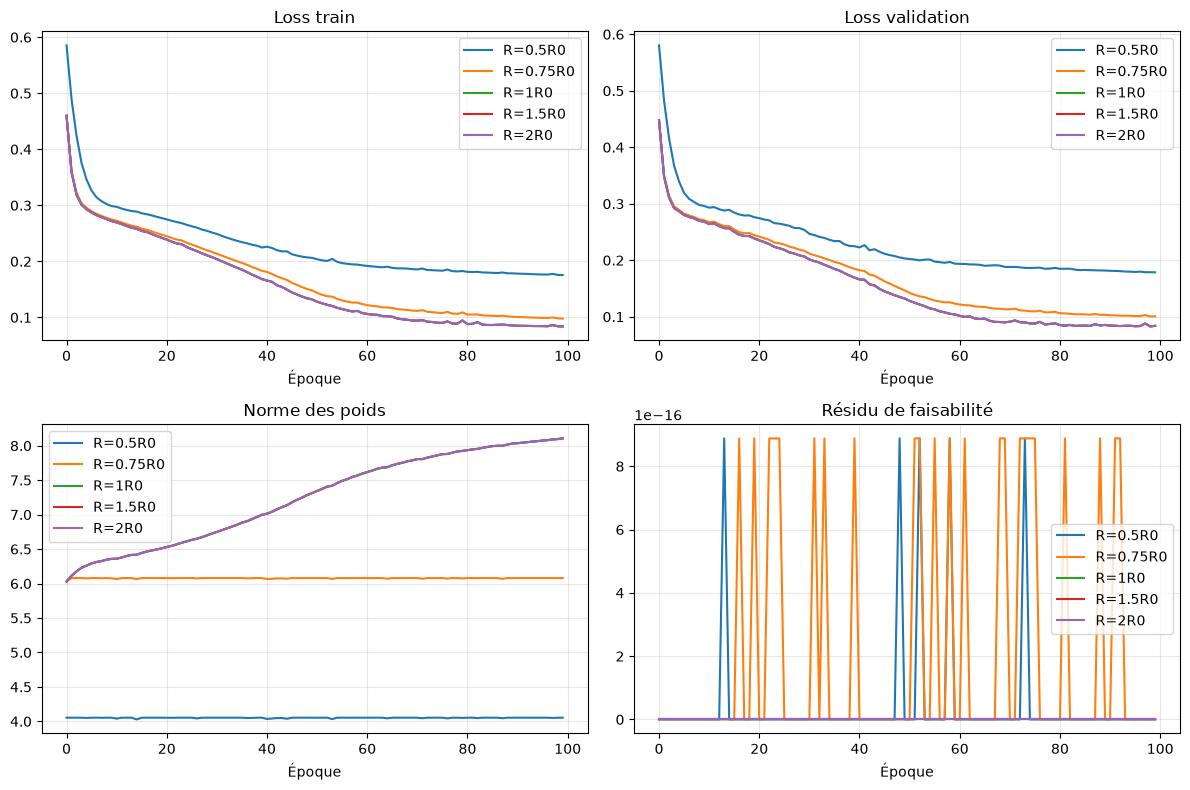

In [3]:
from train import train_model
from plots import plot_constraint_comparison

reference_params, reference_history = train_model(
    X_train, y_train, X_val, y_val, init_params(seed=SEED),
    optimizer="sgd", learning_rate=0.05, epochs=100,
    batch_size=32, seed=SEED,
)
R0 = parameter_norm(reference_params)
print("R0 :", R0)

constraint_factors = [0.5, 0.75, 1.0, 1.5, 2.0]
constraint_histories = {}
constraint_models = {}
for factor in constraint_factors:
    radius = factor * R0
    label = f"R={factor:g}R0"
    params, history = train_model(
        X_train, y_train, X_val, y_val, init_params(seed=SEED),
        optimizer="projected_gradient", learning_rate=0.05,
        epochs=100, batch_size=32, seed=SEED,
        constraint_radius=radius,
    )
    constraint_histories[label] = history
    constraint_models[label] = params
    print(
        f"{label}: train loss={history['train_loss'][-1]:.4f}, "
        f"val loss={history['val_loss'][-1]:.4f}, "
        f"val accuracy={history['val_accuracy'][-1]:.3f}, "
        f"norme={history['parameter_norm'][-1]:.4f}, "
        f"résidu={history['feasibility_residual'][-1]:.2e}, "
        f"active={history['constraint_active'][-1]}"
    )
plot_constraint_comparison(constraint_histories)


### Résultats E2
Le modèle de référence donne `R0 ≈ 8,1065`. Les contraintes sont actives pour `0,5R0`, `0,75R0` et `R0` : les normes atteignent alors leur rayon, avec un résidu de faisabilité nul à la précision numérique. Elles sont inactives pour `1,5R0` et `2R0` ; le modèle conserve sa norme non contrainte `R0`.

Quand `R` diminue, la loss validation augmente : elle vaut environ `0,1786` à `0,5R0`, `0,1007` à `0,75R0` et `0,0840` à `R0`. Une contrainte trop stricte réduit la capacité du modèle.


## F1 — Pénalité L2 et contrainte explicite
Pour chaque valeur de `λ`, on entraîne d’abord le modèle L2, puis on fixe `R` à la norme finale de ses poids. Les deux méthodes utilisent SGD, le même learning rate, la même initialisation et le même budget.


λ=0.001, R=7.5000 | L2: val loss=0.0865, accuracy=0.970 | contrainte: val loss=0.0875, accuracy=0.967
λ=0.01, R=5.0001 | L2: val loss=0.1272, accuracy=0.953 | contrainte: val loss=0.1264, accuracy=0.953
λ=0.1, R=1.9704 | L2: val loss=0.3276, accuracy=0.883 | contrainte: val loss=0.3276, accuracy=0.883


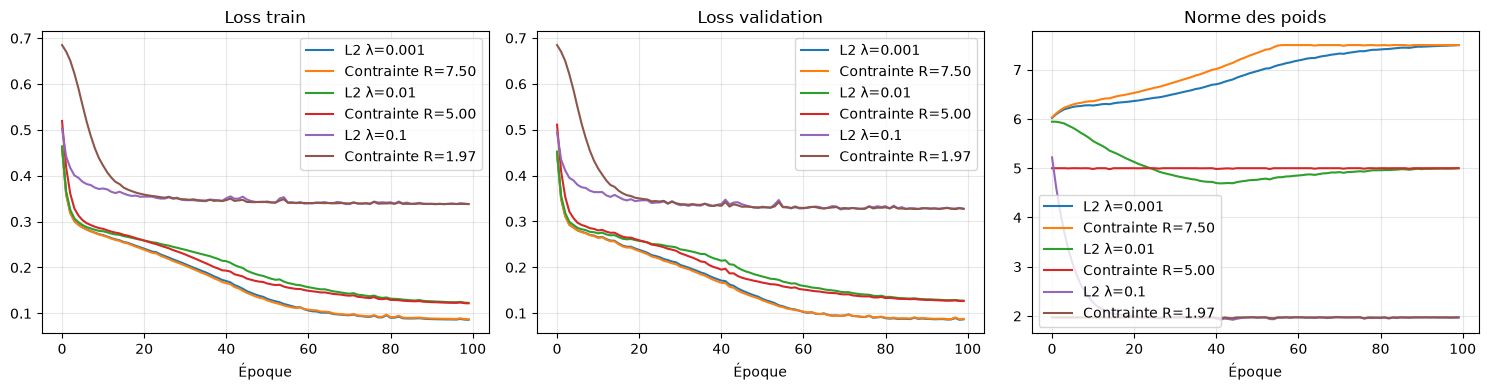

In [5]:
from experiments import compare_l2_with_constraint
from plots import plot_regularization_comparison

l2_constraint_results = {}
comparison_histories = {}
for coefficient in (1e-3, 1e-2, 1e-1):
    result = compare_l2_with_constraint(
        X_train, y_train, X_val, y_val, coefficient,
        learning_rate=0.05, epochs=100, batch_size=32, seed=SEED,
    )
    l2_constraint_results[coefficient] = result
    l2_history = result["l2_history"]
    constraint_history = result["constrained_history"]
    l2_label = f"L2 λ={coefficient:g}"
    constraint_label = f"Contrainte R={result['radius']:.2f}"
    comparison_histories[l2_label] = l2_history
    comparison_histories[constraint_label] = constraint_history
    print(
        f"λ={coefficient:g}, R={result['radius']:.4f} | "
        f"L2: val loss={l2_history['val_loss'][-1]:.4f}, "
        f"accuracy={l2_history['val_accuracy'][-1]:.3f} | "
        f"contrainte: val loss={constraint_history['val_loss'][-1]:.4f}, "
        f"accuracy={constraint_history['val_accuracy'][-1]:.3f}"
    )
plot_regularization_comparison(comparison_histories)


### Analyse F1
Les normes étant appariées, les performances obtenues par pénalité L2 et contrainte sont proches. Pour `λ=0,001` et `R≈7,50`, les losses validation sont `0,0865` (L2) et `0,0875` (contrainte). Pour `λ=0,01` et `R≈5,00`, elles sont `0,1272` et `0,1264`. Pour `λ=0,1` et `R≈1,97`, les deux donnent environ `0,3276`.

Les courbes montrent des trajectoires de norme différentes : la projection maintient les poids sur la frontière quand la contrainte est active, alors que la pénalité L2 laisse la norme évoluer. Malgré cela, à normes finales appariées, les losses validation sont proches : `0,0865` (L2) contre `0,0875` (contrainte) pour `λ=0,001`, `0,1272` contre `0,1264` pour `λ=0,01`, et `0,3276` pour les deux à `λ=0,1`.

La pénalité réduit progressivement la norme via le gradient, tandis que la projection impose directement une borne ; dans ces expériences non convexes, les résultats sont proches sans être identiques. Les grandes pénalisations/rayons petits dégradent la généralisation. Aucun résultat test n’est utilisé ici.
